# TP — MLP en 20 Newsgroups
**Redes Neuronales — Álvaro, legajo 61621**

Partimos del notebook de Regresión Softmax de la cátedra: conservamos datos,
preprocesamiento NLTK, TF-IDF, PyTorch, Optuna, MLflow y TensorBoard. Sustituimos
la capa lineal por 1–3 capas ocultas no lineales y buscamos también activaciones,
anchos y parámetros de Adam, RMSprop y SGD. A continuación se detallan los
rangos de búsqueda, el presupuesto experimental y los criterios de selección.

Las salidas guardadas incluyen las métricas, tablas y figuras de los experimentos.

Fuente base: [notebook original](https://github.com/cselmo/TP-Regresion-Softmax-TNG/blob/9267a2ff7839aad6fdceda2185baedabca9a4697/01_Softmax_Regression_20Newsgroups.ipynb).
Referencias conceptuales de clase: *Multilayer Perceptron*, pp. 22–32;
*Backpropagation*, pp. 3–12; *Optimizadores*, pp. 3–23;
*Regularización*, pp. 7–13, 36–47 y 83–86. Se conservan las secciones 0–9 del
punto de partida y se agregan las comparaciones que requiere MLP.

## 0. Setup y protocolo
Instalar primero las dependencias siguiendo el README, elegir el kernel del
entorno y ejecutar todas las celdas en orden. El notebook no instala paquetes.
Todas las rutas son relativas a esta carpeta; cada Run All crea una ejecución
nueva y entrena desde cero. Se necesita Internet para las descargas iniciales.

Python coordina el experimento; NumPy y pandas manejan arreglos y tablas;
scikit-learn aporta el dataset, TF-IDF y métricas; NLTK procesa texto;
PyTorch implementa red, autograd y optimización. Optuna decide qué configuraciones
ensayar y puede podarlas. MLflow registra parámetros, métricas y artefactos;
TensorBoard permite inspeccionar curvas. Ninguna interfaz necesita estar abierta.


In [1]:
from pathlib import Path
import os
import shutil

ROOT = Path.cwd().resolve()
if not (ROOT / 'RESUELTO_MLP.ipynb').is_file():
    raise RuntimeError('Abrir Jupyter en la carpeta que contiene RESUELTO_MLP.ipynb.')
free_gib = shutil.disk_usage(ROOT).free / 2**30
print(f'Espacio libre: {free_gib:.2f} GiB')
if free_gib < 3:
    raise RuntimeError('Se requieren al menos 3 GiB libres antes de descargar o entrenar.')

# Directorios de datos y resultados de esta ejecución.
os.environ['MPLCONFIGDIR'] = str(ROOT / 'salidas' / 'matplotlib_cache')
os.environ['NLTK_DATA'] = str(ROOT / 'datos' / 'nltk_data')
os.environ['MLFLOW_ENABLE_SYSTEM_METRICS_LOGGING'] = 'false'
os.environ['MLFLOW_LOGGING_LEVEL'] = 'WARNING'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'


Espacio libre: 29.31 GiB


In [2]:
import gc
import hashlib
import importlib.metadata
import json
import math
import platform
import random
import time
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import mlflow
import nltk
import numpy as np
import optuna
import pandas as pd
import psutil
import torch
from IPython.display import Markdown, display
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.tensorboard import SummaryWriter

SEED = 42
SAMPLER_SEED = 2026
NUM_CLASSES = 20
N_TRIALS, SEARCH_EPOCHS = 24, 8
COMPARISON_EPOCHS, FINALIST_EPOCHS = 25, 30
torch.set_num_threads(2)
device = torch.device('cpu')

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_all()
torch.use_deterministic_algorithms(True)
SESSION = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
OUT = ROOT / 'salidas' / 'mlp_20newsgroups' / SESSION
OUT.mkdir(parents=True, exist_ok=False)
DATA = ROOT / 'datos'
DATA.mkdir(exist_ok=True)

def save_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),
                         encoding='utf-8')
    temporary.replace(path)

versions = {p: importlib.metadata.version(p) for p in [
    'torch', 'numpy', 'pandas', 'scikit-learn', 'nltk', 'matplotlib',
    'mlflow', 'optuna', 'tensorboard', 'psutil']}
environment = {'session': SESSION, 'python': platform.python_version(),
               'platform': platform.platform(), 'processor': platform.processor(),
               'logical_cpus': os.cpu_count(), 'physical_cpus': psutil.cpu_count(logical=False),
               'torch_threads': torch.get_num_threads(),
               'ram_available_gib': psutil.virtual_memory().available / 2**30,
               'free_disk_gib': free_gib, 'device': str(device), 'versions': versions,
               'model_seed': SEED, 'sampler_seed': SAMPLER_SEED}
save_json(OUT / 'entorno.json', environment)
display(pd.Series(environment, name='Configuración de ejecución'))
if psutil.virtual_memory().available < 2 * 2**30:
    raise RuntimeError('Se necesitan al menos 2 GiB de RAM disponibles; cerrar aplicaciones y reiniciar Run All.')

TRACKING_URI = 'sqlite:///' + (OUT / 'mlflow.db').as_posix()
mlflow.set_tracking_uri(TRACKING_URI)
EXPERIMENT = mlflow.create_experiment('mlp_20newsgroups',
                                     artifact_location=(OUT / 'artifacts').as_uri())
mlflow.set_experiment(experiment_id=EXPERIMENT)
RECORDS = []
print('Ejecución:', SESSION)


session                                        20261019T203923_277923Z
python                                                          3.12.5
platform                                     Windows-10-10.0.19045-SP0
processor            Intel64 Family 6 Model 142 Stepping 9, Genuine...
logical_cpus                                                         4
physical_cpus                                                        2
torch_threads                                                        2
ram_available_gib                                             6.038139
free_disk_gib                                                29.305653
device                                                             cpu
versions             {'torch': '2.14.0+cpu', 'numpy': '2.5.3', 'pan...
model_seed                                                          42
sampler_seed                                                      2026
Name: Configuración de ejecución, dtype: object

Ejecución: 20261019T203923_277923Z


**Diseño fijado antes de ver resultados.** El split interno es 80/20 estratificado
con semilla 42. Se mantienen los siete HP de Softmax: stopwords, normalización
lingüística, n-gramas, máximo de características, min_df, LR y batch. Optuna hace
24 trials de hasta 8 épocas; maximiza accuracy de validación de la última época
entre los completos. Los primeros seis cubren explícitamente las alternativas
exigidas y no se podan. Los restantes usan TPE (semilla 2026) y MedianPruner,
seis trials de arranque y tres steps de calentamiento (steps desde cero).

Se ensayan 1–3 ocultas, anchos 32/64/128 por capa y ReLU/tanh/sigmoid. Adam
varía beta1 (0.8/0.9) y beta2 (0.99/0.999); RMSprop, alpha (0.9/0.99) y momentum
(0/0.9); SGD, momentum (0/0.9). LR está entre 0.001 y 0.1 en escala logarítmica.
El segundo momento promedia gradientes al cuadrado: no es una derivada segunda.

Luego hay nueve comparaciones de 25 épocas con representación fija; un caso de
sobreajuste [256,128] de 40 épocas (alternativa prevista [512,256,128], 60 épocas,
si no aparece el patrón); y un finalista de 30 épocas para elegir duración por
mínima pérdida de validación. Finalmente se entrena desde cero sobre todo el
train oficial durante la duración elegida y se evalúa test una vez. No se ajusta
nada después de ver test. Presupuestos propios, adaptados a CPU, sin garantía
de óptimo global. La única semilla no permite estimar variabilidad estadística.


In [3]:
nltk.data.path.insert(0, str(DATA / 'nltk_data'))
for resource in ['stopwords', 'wordnet', 'omw-1.4', 'punkt', 'punkt_tab']:
    if not nltk.download(resource, download_dir=str(DATA / 'nltk_data'), quiet=True):
        raise RuntimeError(f'No se pudo descargar el recurso NLTK {resource}.')


## 1. Datos: 20 Newsgroups
Conservamos las 20 categorías y las particiones oficiales del template. Se
remueven headers, footers y quotes para reducir pistas de metadatos. Solo el
train oficial interviene en la búsqueda; no se filtran textos cortos ni se
toman cuatro categorías como en otro ejemplo de clase. El test ya fue conocido
durante el TP anterior: aquí se reserva hasta fijar las decisiones del MLP.


In [4]:
newsgroups_train = fetch_20newsgroups(subset='train', data_home=str(DATA / 'sklearn'),
                                    remove=('headers', 'footers', 'quotes'))
class_names = list(newsgroups_train.target_names)
texts = newsgroups_train.data
labels = np.asarray(newsgroups_train.target, dtype=np.int64)
train_idx, val_idx = train_test_split(np.arange(len(texts)), test_size=0.2,
                                     random_state=SEED, stratify=labels)
assert len(class_names) == NUM_CLASSES
assert not set(train_idx).intersection(val_idx)
assert len(train_idx) + len(val_idx) == len(texts)
split_hash = hashlib.sha256(train_idx.tobytes() + val_idx.tobytes()).hexdigest()
save_json(OUT / 'particion.json', {'seed': SEED, 'n_train': len(train_idx),
          'n_val': len(val_idx), 'n_official_train': len(texts), 'hash_indices': split_hash,
          'train_indices': train_idx.tolist(), 'val_indices': val_idx.tolist()})
display(pd.DataFrame({'clase': class_names,
                     'train_interno': np.bincount(labels[train_idx], minlength=20),
                     'validacion': np.bincount(labels[val_idx], minlength=20)}))


,clase,train_interno,validacion
0,alt.atheism,384,96
1,comp.graphics,467,117
2,comp.os.ms-windows.misc,473,118
3,comp.sys.ibm.pc.hardware,472,118
4,comp.sys.mac.hardware,463,115
5,comp.windows.x,474,119
6,misc.forsale,468,117
7,rec.autos,475,119
8,rec.motorcycles,478,120
9,rec.sport.baseball,478,119


## 2. Preprocesamiento configurable
Igual que en el template: minúsculas, tokenización NLTK, tokens alfabéticos,
eliminación opcional de stopwords y none/stem/lemmatize. WordNet usa su POS
predeterminado; no agregamos análisis morfosintáctico. Stemming recorta formas;
lematización busca formas de diccionario. Esto no es la normalización L2 del
vector TF-IDF. El cache de seis variantes solo aplica reglas fijas a cada texto;
no aprende vocabulario ni IDF y, por eso, no incorpora estadísticas de validación.


In [5]:
STOP_WORDS = set(stopwords.words('english'))
STEMMER, LEMMATIZER = PorterStemmer(), WordNetLemmatizer()

def preprocess_text(text, remove_stopwords, normalization):
    tokens = [t for t in word_tokenize(text.lower()) if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == 'stem':
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == 'lemmatize':
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    elif normalization != 'none':
        raise ValueError(normalization)
    return ' '.join(tokens)

example = 'The researchers were studying the running processes and stopping conditions.'
display(pd.DataFrame([{'stopwords': sw, 'normalization': norm,
                       'texto': preprocess_text(example, sw, norm)}
                      for sw in [False, True] for norm in ['none', 'stem', 'lemmatize']]))


,stopwords,normalization,texto
0,False,none,the researchers were studying the running proc...
1,False,stem,the research were studi the run process and st...
2,False,lemmatize,the researcher were studying the running proce...
3,True,none,researchers studying running processes stoppin...
4,True,stem,research studi run process stop condit
5,True,lemmatize,researcher studying running process stopping c...


## 3. Vectorización TF-IDF
`fit_transform` aprende vocabulario e IDF solo del entrenamiento; validación y
test usan `transform`. Conservamos la normalización L2 por documento y el IDF
suavizado predeterminados, a diferencia del ejemplo didáctico de TF-IDF sin
normalizar de otra notebook de clase. No añadimos una segunda normalización.
Usar float32 desde la matriz dispersa evita una copia densa float64 transitoria.
La densificación sigue el template y requiere memoria, especialmente con 10000
características. El vectorizador se vuelve a ajustar para cada trial.


In [6]:
def vectorize_data(train_texts, other_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features,
                                min_df=min_df, dtype=np.float32)
    x_train = vectorizer.fit_transform(train_texts)
    x_other = vectorizer.transform(other_texts)
    return x_train, x_other, vectorizer

def to_tensor_dataset(x, y):
    return TensorDataset(torch.from_numpy(x.astype(np.float32).toarray()),
                         torch.as_tensor(np.asarray(y), dtype=torch.long))


## 4. Modelo MLP
Una capa afín seguida de una no linealidad forma cada oculta. Dos capas lineales
consecutivas sin activación se pueden componer en una sola transformación afín;
no aportan la capacidad no lineal que pide este TP. La última capa produce 20
**logits**, no probabilidades. `CrossEntropyLoss` aplica internamente la operación
log-softmax combinada con la pérdida; agregar softmax antes cambia el problema
y comprime indebidamente los valores que recibe la pérdida.

ReLU no satura para entradas positivas; tanh y sigmoid pueden saturar, dificultando
el flujo de gradientes. Eso no determina por sí solo cuál funcionará mejor aquí.
Usamos Xavier uniforme gain=1 y bias cero en todas las capas y activaciones, de
modo explícito y fijo. No exploramos inicializadores, dropout ni weight decay.
Para D entradas, ocultas h1...hL y bias, el número de parámetros es
`(D+1)h1 + Σ(hl-1+1)hl + (hL+1)20`. Mayor capacidad no garantiza generalización.


In [7]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, activation, num_classes=NUM_CLASSES):
        super().__init__()
        if not 1 <= len(hidden_sizes) <= 3:
            raise ValueError('La consigna permite entre una y tres ocultas.')
        activations = {'relu': nn.ReLU, 'tanh': nn.Tanh, 'sigmoid': nn.Sigmoid}
        layers = []
        previous = input_dim
        for width in hidden_sizes:
            layers.extend([nn.Linear(previous, width), activations[activation]()])
            previous = width
        layers.append(nn.Linear(previous, num_classes))
        self.layers = nn.Sequential(*layers)
        for layer in self.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight, gain=1.0)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.layers(x)

def hidden_sizes(config):
    return [int(config[f'h{i+1}']) for i in range(int(config['n_layers']))]

def make_optimizer(model, config):
    common = {'lr': config['lr'], 'weight_decay': 0}
    if config['optimizer'] == 'Adam':
        return torch.optim.Adam(model.parameters(),
                                betas=(config['beta1'], config['beta2']), **common)
    if config['optimizer'] == 'RMSprop':
        return torch.optim.RMSprop(model.parameters(), alpha=config['alpha'],
                                   momentum=config['rms_momentum'], **common)
    if config['optimizer'] == 'SGD':
        return torch.optim.SGD(model.parameters(), momentum=config['sgd_momentum'], **common)
    raise ValueError(config['optimizer'])


## 5. Entrenamiento e instrumentación
Conservamos el ciclo zero_grad → logits → pérdida → backward → step. Autograd
calcula gradientes por regla de la cadena; el optimizador decide cómo usarlos.
SGD con momentum guarda memoria de actualizaciones; RMSprop escala usando un
promedio del gradiente al cuadrado (alpha); Adam guarda primer y segundo momento
(beta1/beta2) con corrección del sesgo inicial. Todos tienen pesos nuevos por caso.

La pérdida se pondera por muestras, incluyendo el último batch. `train_online`
mide mientras cambian los pesos; `train_fixed` y validación evalúan al final de
cada época con pesos fijos, `eval()` y `no_grad()`. Estas últimas curvas permiten
diagnosticar sobreajuste sin confundir esa asimetría del template.

Tiempo de ajuste: solo batches de actualización. Tiempo de ciclo: ajuste,
evaluaciones de train/validación y envío de métricas a MLflow/TensorBoard. La
preparación de datos/modelo se mide aparte; descargas e instalación se excluyen.
Comparar épocas no equivale a comparar pasos o segundos. Se usa CPU con dos hilos.
Los archivos JSON se actualizan después de cada época; MLflow y TensorBoard tienen
una corrida propia por entrenamiento y rutas exclusivas de esta ejecución MLP.


In [8]:
def make_loaders(train_dataset, other_dataset, batch_size):
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              generator=generator, num_workers=0)
    fixed_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    other_loader = None if other_dataset is None else DataLoader(
        other_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    return train_loader, fixed_loader, other_loader

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, count = 0., 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(device))
            loss = criterion(logits, yb.to(device))
            if not torch.isfinite(loss):
                raise FloatingPointError('Pérdida de evaluación no finita.')
            total_loss += float(loss) * len(yb)
            correct += int((logits.argmax(1).cpu() == yb).sum())
            count += len(yb)
    return total_loss / count, correct / count

def run_training(name, phase, config, data, epochs, trial=None, data_info=None):
    if shutil.disk_usage(ROOT).free < 0.5 * 2**30:
        raise RuntimeError('Espacio insuficiente para continuar guardando evidencia.')
    seed_all()
    setup_start = time.perf_counter()
    model = MLP(data[0].tensors[0].shape[1], hidden_sizes(config), config['activation']).to(device)
    optimizer = make_optimizer(model, config)
    criterion = nn.CrossEntropyLoss()
    train_loader, fixed_loader, other_loader = make_loaders(*data, config['batch_size'])
    record = {'name': name, 'phase': phase, 'config': dict(config), 'state': 'RUNNING',
              'seed': SEED, 'input_dim': data[0].tensors[0].shape[1],
              'parameters': sum(p.numel() for p in model.parameters()), 'requested_epochs': epochs,
              'train_samples': len(data[0]), 'eval_samples': 0 if data[1] is None else len(data[1]),
              'data_info': data_info or {}, 'history': [],
              'model_setup_sec': time.perf_counter() - setup_start}
    RECORDS.append(record)
    writer = SummaryWriter(str(OUT / 'tensorboard' / name))
    history_path = OUT / f'{name}.json'
    with mlflow.start_run(run_name=name) as run:
        record['mlflow_run_id'] = run.info.run_id
        mlflow.log_params({**config, 'hidden_sizes': str(hidden_sizes(config)), 'seed': SEED,
                           'phase': phase, 'parameters': record['parameters'],
                           'input_dim': record['input_dim'], 'requested_epochs': epochs,
                           'initialization': 'xavier_uniform_gain_1_bias_0', 'weight_decay': 0})
        mlflow.set_tag('session', SESSION)
        try:
            for epoch in range(1, epochs + 1):
                cycle_start = time.perf_counter()
                model.train()
                loss_sum, correct, count = 0., 0, 0
                for xb, yb in train_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    optimizer.zero_grad()
                    logits = model(xb)
                    loss = criterion(logits, yb)
                    if not torch.isfinite(loss):
                        raise FloatingPointError('Pérdida de entrenamiento no finita.')
                    loss.backward()
                    optimizer.step()
                    loss_sum += float(loss.detach()) * len(yb)
                    correct += int((logits.argmax(1) == yb).sum())
                    count += len(yb)
                update_sec = time.perf_counter() - cycle_start
                evaluation_start = time.perf_counter()
                train_loss, train_acc = evaluate(model, fixed_loader, criterion)
                metrics = {'train_online_loss': loss_sum / count, 'train_online_acc': correct / count,
                           'train_fixed_loss': train_loss, 'train_fixed_acc': train_acc}
                if other_loader is not None:
                    val_loss, val_acc = evaluate(model, other_loader, criterion)
                    metrics.update(val_loss=val_loss, val_acc=val_acc)
                evaluation_sec = time.perf_counter() - evaluation_start
                row = {'epoch': epoch, 'updates': len(train_loader), 'update_sec': update_sec,
                       'evaluation_sec': evaluation_sec, **metrics}
                logging_start = time.perf_counter()
                mlflow.log_metrics(metrics, step=epoch)
                for key, value in metrics.items():
                    writer.add_scalar(key, value, epoch)
                writer.flush()
                row['logging_sec'] = time.perf_counter() - logging_start
                row['cycle_sec'] = time.perf_counter() - cycle_start
                row['cumulative_cycle_sec'] = sum(h['cycle_sec'] for h in record['history']) + row['cycle_sec']
                record['history'].append(row)
                # Persistencia JSON, prints y cierre de corrida quedan fuera del tiempo de ciclo.
                save_json(history_path, record)
                print(f'{name}: época {epoch:02d}/{epochs}, train={train_acc:.3f}' +
                      (f', val={metrics["val_acc"]:.3f}' if 'val_acc' in metrics else '') +
                      f', ciclo={row["cycle_sec"]:.1f}s', flush=True)
                if trial is not None:
                    trial.report(metrics['val_acc'], step=epoch - 1)
                    if trial.should_prune():
                        record['state'] = 'PRUNED'
                        raise optuna.TrialPruned(f'Podado después de {epoch} épocas.')
            record['state'] = 'COMPLETE'
        except optuna.TrialPruned:
            mlflow.set_tag('training_state', 'PRUNED')
            raise
        except Exception as exc:
            record['state'] = 'FAIL'
            record['error'] = f'{type(exc).__name__}: {exc}'
            mlflow.set_tag('training_state', 'FAIL')
            raise
        finally:
            writer.close()
            record['executed_epochs'] = len(record['history'])
            record['update_sec'] = sum(h['update_sec'] for h in record['history'])
            record['cycle_sec'] = sum(h.get('cycle_sec', 0.) for h in record['history'])
            save_json(history_path, record)
            mlflow.set_tag('training_state', record['state'])
            mlflow.log_metrics({'executed_epochs': record['executed_epochs'],
                               'update_seconds': record['update_sec'], 'cycle_seconds': record['cycle_sec']})
            mlflow.log_artifact(str(history_path), artifact_path='history')
            if record['state'] == 'PRUNED':
                # MLflow no tiene estado PRUNED: KILLED + tag evita confundirlo con un fallo.
                mlflow.end_run(status='KILLED')
    return record, model


## 6. Búsqueda de hiperparámetros con Optuna
Primero precalculamos las seis variantes lingüísticas, como en el template.
Cada trial ajusta su TF-IDF con train interno y transforma validación. Los
anchos y parámetros del optimizador se sugieren condicionalmente: no se asigna
h3 a una red de una oculta ni beta2 a SGD. Los seis trials encolados garantizan
cobertura, pero cambian varios factores a la vez y no aíslan efectos causales.

Pruning de Optuna corta configuraciones poco prometedoras frente a otras; no
elimina pesos ni neuronas. Se reporta accuracy después de cada época y se lanza
`TrialPruned` al cortar. Los casos completos posteriores no usan poda, para
conservar su dinámica. Un trial podado carece de métricas de las épocas omitidas;
no rellenamos esas curvas ni lo comparamos como si hubiese terminado ocho épocas.


In [10]:
preprocessed_cache = {}
preprocessing_times = {}
for remove_sw in [False, True]:
    for normalization in ['none', 'stem', 'lemmatize']:
        started = time.perf_counter()
        preprocessed_cache[remove_sw, normalization] = [
            preprocess_text(t, remove_sw, normalization) for t in texts]
        seconds = time.perf_counter() - started
        preprocessing_times[f'{remove_sw}/{normalization}'] = seconds
        print(f'Preprocesamiento stopwords={remove_sw}, {normalization}: {seconds:.1f}s', flush=True)
save_json(OUT / 'preprocesamiento.json', preprocessing_times)

def make_representation(config, full_train=False, other_texts=None, other_labels=None):
    start = time.perf_counter()
    processed = preprocessed_cache[config['remove_stopwords'], config['normalization']]
    if full_train:
        train_texts, train_labels = processed, labels
        preprocess_start = time.perf_counter()
        other_processed = [preprocess_text(t, config['remove_stopwords'], config['normalization'])
                           for t in other_texts]
        extra_preprocessing_sec = time.perf_counter() - preprocess_start
    else:
        train_texts = [processed[i] for i in train_idx]
        other_processed = [processed[i] for i in val_idx]
        train_labels, other_labels = labels[train_idx], labels[val_idx]
        extra_preprocessing_sec = 0.
    vector_start = time.perf_counter()
    x_train, x_other, vectorizer = vectorize_data(
        train_texts, other_processed,
        (1, 1) if config['ngram_range'] == '1gram' else (1, 2),
        config['max_features'], config['min_df'])
    vectorization_sec = time.perf_counter() - vector_start
    dense_bytes = (x_train.shape[0] + x_other.shape[0]) * x_train.shape[1] * 4
    if psutil.virtual_memory().available < dense_bytes * 1.5 + 512 * 2**20:
        raise MemoryError('RAM disponible insuficiente para densificar esta representación.')
    conversion_start = time.perf_counter()
    train_dataset = to_tensor_dataset(x_train, train_labels)
    other_dataset = to_tensor_dataset(x_other, other_labels)
    conversion_sec = time.perf_counter() - conversion_start
    info = {'vectorization_sec': vectorization_sec, 'conversion_sec': conversion_sec,
            'extra_preprocessing_sec': extra_preprocessing_sec,
            'preparation_sec': time.perf_counter() - start,
            'dense_mib': dense_bytes / 2**20, 'full_train': full_train,
            'shared_preprocessed_key': f'{config["remove_stopwords"]}/{config["normalization"]}'}
    return (train_dataset, other_dataset), vectorizer, info

def suggest_config(trial):
    config = {
        'remove_stopwords': trial.suggest_categorical('remove_stopwords', [False, True]),
        'normalization': trial.suggest_categorical('normalization', ['none', 'stem', 'lemmatize']),
        'ngram_range': trial.suggest_categorical('ngram_range', ['1gram', '1_2gram']),
        'max_features': trial.suggest_categorical('max_features', [2000, 5000, 10000]),
        'min_df': trial.suggest_categorical('min_df', [1, 2, 5]),
        'lr': trial.suggest_float('lr', 1e-3, 1e-1, log=True),
        'batch_size': trial.suggest_categorical('batch_size', [32, 64, 128]),
        'n_layers': trial.suggest_categorical('n_layers', [1, 2, 3]),
        'activation': trial.suggest_categorical('activation', ['relu', 'tanh', 'sigmoid']),
        'optimizer': trial.suggest_categorical('optimizer', ['Adam', 'RMSprop', 'SGD'])}
    for i in range(config['n_layers']):
        config[f'h{i+1}'] = trial.suggest_categorical(f'h{i+1}', [32, 64, 128])
    if config['optimizer'] == 'Adam':
        config['beta1'] = trial.suggest_categorical('beta1', [0.8, 0.9])
        config['beta2'] = trial.suggest_categorical('beta2', [0.99, 0.999])
    elif config['optimizer'] == 'RMSprop':
        config['alpha'] = trial.suggest_categorical('alpha', [0.9, 0.99])
        config['rms_momentum'] = trial.suggest_categorical('rms_momentum', [0.0, 0.9])
    else:
        config['sgd_momentum'] = trial.suggest_categorical('sgd_momentum', [0.0, 0.9])
    return config

coverage_trials = [
    dict(remove_stopwords=True, normalization='lemmatize', ngram_range='1gram',
         max_features=5000, min_df=2, lr=0.003, batch_size=128,
         n_layers=1, h1=64, activation='relu', optimizer='Adam', beta1=0.9, beta2=0.999),
    dict(remove_stopwords=False, normalization='none', ngram_range='1_2gram',
         max_features=2000, min_df=1, lr=0.001, batch_size=64,
         n_layers=2, h1=64, h2=32, activation='tanh', optimizer='RMSprop', alpha=0.9, rms_momentum=0.),
    dict(remove_stopwords=True, normalization='stem', ngram_range='1gram',
         max_features=10000, min_df=5, lr=0.1, batch_size=32,
         n_layers=3, h1=128, h2=64, h3=32, activation='sigmoid', optimizer='SGD', sgd_momentum=0.),
    dict(remove_stopwords=False, normalization='lemmatize', ngram_range='1_2gram',
         max_features=10000, min_df=1, lr=0.01, batch_size=64,
         n_layers=3, h1=32, h2=64, h3=128, activation='relu', optimizer='Adam', beta1=0.8, beta2=0.99),
    dict(remove_stopwords=True, normalization='none', ngram_range='1gram',
         max_features=5000, min_df=5, lr=0.001, batch_size=32,
         n_layers=1, h1=128, activation='tanh', optimizer='RMSprop', alpha=0.99, rms_momentum=0.9),
    dict(remove_stopwords=False, normalization='stem', ngram_range='1_2gram',
         max_features=2000, min_df=2, lr=0.1, batch_size=128,
         n_layers=2, h1=32, h2=64, activation='sigmoid', optimizer='SGD', sgd_momentum=0.9),
]

class CoverageMedianPruner(optuna.pruners.MedianPruner):
    def prune(self, study, trial):
        return False if trial.number < len(coverage_trials) else super().prune(study, trial)

study = optuna.create_study(
    study_name='mlp_20newsgroups', direction='maximize',
    storage='sqlite:///' + (OUT / 'optuna.db').as_posix(),
    sampler=optuna.samplers.TPESampler(seed=SAMPLER_SEED),
    pruner=CoverageMedianPruner(n_startup_trials=6, n_warmup_steps=3, interval_steps=1))
for config in coverage_trials:
    study.enqueue_trial(config)

def objective(trial):
    config = suggest_config(trial)
    data, vectorizer, data_info = make_representation(config)
    try:
        result, model = run_training(f'trial_{trial.number:02d}', 'search', config,
                                     data, SEARCH_EPOCHS, trial=trial, data_info=data_info)
        value = result['history'][-1]['val_acc']
        del model
        return value
    finally:
        del data, vectorizer
        gc.collect()

study.optimize(objective, n_trials=N_TRIALS, n_jobs=1, catch=(FloatingPointError,))
study.trials_dataframe().to_csv(OUT / 'trials_optuna.csv', index=False)
best = dict(study.best_params)
save_json(OUT / 'mejores_hiperparametros.json', best)
print('Mejor trial completo:', study.best_trial.number, 'accuracy val:', study.best_value)
display(pd.Series(best, name='Mejor configuración'))


Preprocesamiento stopwords=False, none: 22.8s


Preprocesamiento stopwords=False, stem: 83.6s


Preprocesamiento stopwords=False, lemmatize: 45.9s


Preprocesamiento stopwords=True, none: 29.0s


Preprocesamiento stopwords=True, stem: 66.0s


...

trial_23: época 07/8, train=0.973, val=0.696, ciclo=6.0s


trial_23: época 08/8, train=0.973, val=0.699, ciclo=6.3s


[I 2026-10-19 18:00:33,177] Trial 23 finished with value: 0.6986301369863014 and parameters: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 5, 'lr': 0.007190068638194487, 'batch_size': 32, 'n_layers': 1, 'activation': 'relu', 'optimizer': 'Adam', 'h1': 128, 'beta1': 0.9, 'beta2': 0.99}. Best is trial 17 with value: 0.7118868758285462.


Mejor trial completo: 17 accuracy val: 0.7118868758285462


remove_stopwords         True
normalization       lemmatize
ngram_range             1gram
max_features            10000
min_df                      2
lr                   0.002728
batch_size                 32
n_layers                    1
activation               relu
optimizer                Adam
h1                        128
beta1                     0.9
beta2                    0.99
Name: Mejor configuración, dtype: object

In [11]:
search_records = [r for r in RECORDS if r['phase'] == 'search']
complete_configs = [r['config'] for r in search_records if r['state'] == 'COMPLETE']
coverage = {}
for key, expected in {
    'remove_stopwords': {False, True}, 'normalization': {'none', 'stem', 'lemmatize'},
    'ngram_range': {'1gram', '1_2gram'}, 'max_features': {2000, 5000, 10000},
    'min_df': {1, 2, 5}, 'batch_size': {32, 64, 128}, 'n_layers': {1, 2, 3},
    'activation': {'relu', 'tanh', 'sigmoid'}, 'optimizer': {'Adam', 'RMSprop', 'SGD'},
    'beta1': {0.8, 0.9}, 'beta2': {0.99, 0.999}, 'alpha': {0.9, 0.99},
    'rms_momentum': {0., 0.9}, 'sgd_momentum': {0., 0.9}}.items():
    seen = {c[key] for c in complete_configs if key in c}
    coverage[key] = {'expected': sorted(expected), 'seen_complete': sorted(seen),
                     'covered': expected <= seen}
widths_seen = {v for c in complete_configs for k, v in c.items() if k in ['h1', 'h2', 'h3']}
coverage['hidden_widths'] = {'expected': [32, 64, 128], 'seen_complete': sorted(widths_seen),
                             'covered': {32, 64, 128} <= widths_seen}
coverage['lr'] = {'seen_complete': sorted({c['lr'] for c in complete_configs}),
                  'covered': len({c['lr'] for c in complete_configs}) > 1}
save_json(OUT / 'cobertura.json', coverage)
display(pd.DataFrame(coverage).T)
assert all(item['covered'] for item in coverage.values()), 'Falta cobertura efectiva: revisar antes de continuar.'


,expected,seen_complete,covered
remove_stopwords,"[False, True]","[False, True]",True
normalization,"[lemmatize, none, stem]","[lemmatize, none, stem]",True
ngram_range,"[1_2gram, 1gram]","[1_2gram, 1gram]",True
max_features,"[2000, 5000, 10000]","[2000, 5000, 10000]",True
min_df,"[1, 2, 5]","[1, 2, 5]",True
batch_size,"[32, 64, 128]","[32, 64, 128]",True
n_layers,"[1, 2, 3]","[1, 2, 3]",True
activation,"[relu, sigmoid, tanh]","[relu, sigmoid, tanh]",True
optimizer,"[Adam, RMSprop, SGD]","[Adam, RMSprop, SGD]",True
beta1,"[0.8, 0.9]","[0.8, 0.9]",True


### 6.1. Comparaciones controladas y sobreajuste
Se fija el preprocesamiento/TF-IDF elegido por Optuna y se reutiliza exactamente
la misma matriz entre los nueve casos. Cada uno se inicializa de nuevo. Referencia:
1×64, ReLU, Adam (0.9,0.999), LR=0.01, batch=128; las otras filas cambian solo
ancho, profundidad, activación u optimizador. El mismo LR compara un punto de
operación, no la mejor configuración posible de cada familia. La semilla común
reduce algunas diferencias aleatorias; entre arquitecturas de distinto tamaño
no produce pesos idénticos ni elimina la variabilidad entre ejecuciones.

Para demostrar sobreajuste se amplía la capacidad con el resto fijo: [256,128],
ReLU, Adam, LR=0.003, 40 épocas sin poda. Si no cumple el diagnóstico predefinido,
se ejecuta [512,256,128] durante 60. Se requieren brecha train fijo–val ≥0.10,
media final de train loss < mitad de la inicial y media final de val loss >1.05
veces su mínimo móvil de cinco épocas. El tamaño de una red, por sí solo, no
demuestra sobreajuste. No se cambian etiquetas, split ni cantidad de documentos.


In [12]:
comparison_data, comparison_vectorizer, comparison_info = make_representation(best)
reference_config = {**best, 'n_layers': 1, 'h1': 64, 'activation': 'relu',
                    'optimizer': 'Adam', 'beta1': 0.9, 'beta2': 0.999,
                    'lr': 0.01, 'batch_size': 128}
# Limpiar parámetros condicionales inactivos para no atribuirlos a un optimizador distinto.
def active_config(config):
    config = dict(config)
    for i in range(config['n_layers'] + 1, 4):
        config.pop(f'h{i}', None)
    conditional = {'Adam': {'beta1', 'beta2'}, 'RMSprop': {'alpha', 'rms_momentum'},
                   'SGD': {'sgd_momentum'}}
    for key in {'beta1', 'beta2', 'alpha', 'rms_momentum', 'sgd_momentum'} - conditional[config['optimizer']]:
        config.pop(key, None)
    return config

comparison_changes = [
    ('referencia', {}), ('ancho_32', {'h1': 32}), ('ancho_128', {'h1': 128}),
    ('ocultas_2', {'n_layers': 2, 'h2': 64}),
    ('ocultas_3', {'n_layers': 3, 'h2': 64, 'h3': 64}),
    ('tanh', {'activation': 'tanh'}), ('sigmoid', {'activation': 'sigmoid'}),
    ('RMSprop', {'optimizer': 'RMSprop', 'alpha': 0.99, 'rms_momentum': 0.}),
    ('SGD', {'optimizer': 'SGD', 'sgd_momentum': 0.9}),
]
comparison_records = []
for name, changes in comparison_changes:
    config = active_config({**reference_config, **changes})
    result, model = run_training('comparacion_' + name, 'comparison', config,
                                 comparison_data, COMPARISON_EPOCHS,
                                 data_info={**comparison_info, 'shared_representation': True})
    comparison_records.append(result)
    del model
    gc.collect()

def overfit_diagnosis(record):
    h = pd.DataFrame(record['history'])
    train_start = float(h['train_fixed_loss'].head(5).mean())
    train_end = float(h['train_fixed_loss'].tail(5).mean())
    val_end = float(h['val_loss'].tail(5).mean())
    val_min = float(h['val_loss'].rolling(5).mean().min())
    gap = float(h['train_fixed_acc'].iloc[-1] - h['val_acc'].iloc[-1])
    return {'accuracy_gap': gap, 'train_loss_first5': train_start,
            'train_loss_last5': train_end, 'val_loss_last5': val_end,
            'min_rolling5_val_loss': val_min,
            'demonstrated': bool(gap >= 0.10 and train_end < 0.5 * train_start and val_end > 1.05 * val_min)}

overfit_records = []
for widths, epochs in [([256, 128], 40), ([512, 256, 128], 60)]:
    config = active_config({**reference_config, 'n_layers': len(widths),
                            **{f'h{i+1}': w for i, w in enumerate(widths)}, 'lr': 0.003})
    result, model = run_training('sobreajuste_' + '_'.join(map(str, widths)), 'overfit',
                                 config, comparison_data, epochs,
                                 data_info={**comparison_info, 'shared_representation': True})
    result['overfit_diagnosis'] = overfit_diagnosis(result)
    save_json(OUT / (result['name'] + '.json'), result)
    overfit_records.append(result)
    display(pd.Series(result['overfit_diagnosis'], name=result['name']))
    del model
    gc.collect()
    if result['overfit_diagnosis']['demonstrated']:
        break
assert any(r['overfit_diagnosis']['demonstrated'] for r in overfit_records), (
    'Los casos previstos no demuestran sobreajuste: conservar la evidencia y definir otro experimento.')
del comparison_data, comparison_vectorizer
gc.collect()


comparacion_referencia: época 01/25, train=0.894, val=0.722, ciclo=2.1s


comparacion_referencia: época 02/25, train=0.960, val=0.720, ciclo=2.1s


comparacion_referencia: época 03/25, train=0.972, val=0.727, ciclo=1.9s


comparacion_referencia: época 04/25, train=0.971, val=0.721, ciclo=2.0s


comparacion_referencia: época 05/25, train=0.973, val=0.724, ciclo=2.0s


...

sobreajuste_256_128: época 38/40, train=0.973, val=0.702, ciclo=2.8s


sobreajuste_256_128: época 39/40, train=0.973, val=0.703, ciclo=2.8s


sobreajuste_256_128: época 40/40, train=0.973, val=0.704, ciclo=3.5s


accuracy_gap             0.269551
train_loss_first5        0.207351
train_loss_last5           0.0855
val_loss_last5           1.570497
min_rolling5_val_loss     1.10367
demonstrated                 True
Name: sobreajuste_256_128, dtype: object

0

## 7. Entrenamiento final
La búsqueda seleccionó HP usando accuracy al terminar ocho épocas. Para definir
cuánto entrenar el finalista, ahora se entrena nuevamente hasta 30 épocas con
el split interno y se elige la primera época de mínima pérdida de validación,
regla fijada antes de ver test. Después se descartan esos pesos: ajustamos TF-IDF
sobre todo el train oficial y entrenamos otro MLP desde cero durante esa duración.

Esta es una modificación explícita de la celda final del template: no evaluamos
test por época. La única evaluación final no interviene en la selección de HP ni
en la elección de la época. No se restaura el checkpoint del mejor trial.


In [13]:
finalist_data, finalist_vectorizer, finalist_info = make_representation(best)
finalist_record, finalist_model = run_training('finalista_validacion', 'finalist', best,
                                              finalist_data, FINALIST_EPOCHS,
                                              data_info=finalist_info)
selected_epochs = 1 + int(np.argmin([h['val_loss'] for h in finalist_record['history']]))
save_json(OUT / 'seleccion_final.json', {'config': best, 'selected_epochs': selected_epochs,
          'rule': 'first_argmin_validation_loss_in_30_epochs',
          'validation_accuracy_selected_epoch': finalist_record['history'][selected_epochs - 1]['val_acc']})
print('Duración final fijada con validación:', selected_epochs, 'épocas')
del finalist_model, finalist_data, finalist_vectorizer
gc.collect()

newsgroups_test = fetch_20newsgroups(subset='test', data_home=str(DATA / 'sklearn'),
                                   remove=('headers', 'footers', 'quotes'))
assert list(newsgroups_test.target_names) == class_names
final_data, final_vectorizer, final_info = make_representation(
    best, full_train=True, other_texts=newsgroups_test.data, other_labels=newsgroups_test.target)
# El loop final recibe solo train: no puede consultar test durante el ajuste.
final_record, final_model = run_training('modelo_final', 'final', best,
                                        (final_data[0], None), selected_epochs, data_info=final_info)
torch.save({'state_dict': final_model.state_dict(), 'config': best,
            'input_dim': final_record['input_dim'], 'class_names': class_names,
            'epochs': selected_epochs, 'seed': SEED}, OUT / 'modelo_final.pt')
with mlflow.start_run(run_id=final_record['mlflow_run_id']):
    mlflow.log_artifact(str(OUT / 'modelo_final.pt'), artifact_path='model')
    save_json(OUT / 'vocabulario_final.json', {'vocabulary': {k: int(v) for k, v in final_vectorizer.vocabulary_.items()},
              'idf': final_vectorizer.idf_.tolist(), 'norm': final_vectorizer.norm})
    mlflow.log_artifact(str(OUT / 'vocabulario_final.json'), artifact_path='model')


finalista_validacion: época 01/30, train=0.878, val=0.724, ciclo=3.6s


finalista_validacion: época 02/30, train=0.953, val=0.726, ciclo=3.4s


finalista_validacion: época 03/30, train=0.969, val=0.728, ciclo=3.3s


finalista_validacion: época 04/30, train=0.972, val=0.722, ciclo=3.3s


finalista_validacion: época 05/30, train=0.972, val=0.721, ciclo=3.5s


...

finalista_validacion: época 29/30, train=0.973, val=0.693, ciclo=3.4s


finalista_validacion: época 30/30, train=0.973, val=0.690, ciclo=3.5s


Duración final fijada con validación: 2 épocas


modelo_final: época 01/2, train=0.884, ciclo=4.2s


modelo_final: época 02/2, train=0.951, ciclo=3.9s


## 8. Evaluación final y análisis de los entrenamientos
Accuracy resume aciertos totales; F1 macro pondera cada clase por igual y el
informe por clase muestra diferencias que la cifra global oculta. La confusión
y los textos de errores sirven para formular hipótesis de contenido. No prueban
por sí solos por qué falló una red. No se reajusta el modelo después de esta celda.


In [14]:
final_model.eval()
test_loader = DataLoader(final_data[1], batch_size=best['batch_size'], shuffle=False)
predictions, truths = [], []
test_started = time.perf_counter()
with torch.no_grad():
    for xb, yb in test_loader:
        predictions.extend(final_model(xb.to(device)).argmax(1).cpu().tolist())
        truths.extend(yb.tolist())
test_sec = time.perf_counter() - test_started
predictions, truths = np.asarray(predictions), np.asarray(truths)
test_accuracy = float(accuracy_score(truths, predictions))
test_f1_macro = float(f1_score(truths, predictions, average='macro'))
test_results = {'accuracy': test_accuracy, 'f1_macro': test_f1_macro, 'evaluation_sec': test_sec,
                'samples': len(truths), 'selected_epochs': selected_epochs}
save_json(OUT / 'test.json', test_results)
report = classification_report(truths, predictions, target_names=class_names,
                                output_dict=True, zero_division=0)
display(pd.Series(test_results, name='Test final'))
display(pd.DataFrame(report).T)
save_json(OUT / 'classification_report.json', report)
with mlflow.start_run(run_id=final_record['mlflow_run_id']):
    mlflow.log_metrics({'test_accuracy': test_accuracy, 'test_f1_macro': test_f1_macro,
                        'test_evaluation_seconds': test_sec})
    mlflow.log_artifact(str(OUT / 'test.json'))
    mlflow.log_artifact(str(OUT / 'classification_report.json'))


accuracy              0.678173
f1_macro              0.668141
evaluation_sec        0.506884
samples            7532.000000
selected_epochs       2.000000
Name: Test final, dtype: float64

,precision,recall,f1-score,support
alt.atheism,0.598086,0.391850,0.473485,319.000000
comp.graphics,0.555324,0.683805,0.612903,389.000000
comp.os.ms-windows.misc,0.629428,0.586294,0.607096,394.000000
comp.sys.ibm.pc.hardware,0.634715,0.625000,0.629820,392.000000
comp.sys.mac.hardware,0.721311,0.685714,0.703063,385.000000
comp.windows.x,0.838488,0.617722,0.711370,395.000000
misc.forsale,0.763092,0.784615,0.773704,390.000000
rec.autos,0.461890,0.765152,0.576046,396.000000
rec.motorcycles,0.726161,0.746231,0.736059,398.000000
rec.sport.baseball,0.909621,0.785894,0.843243,397.000000


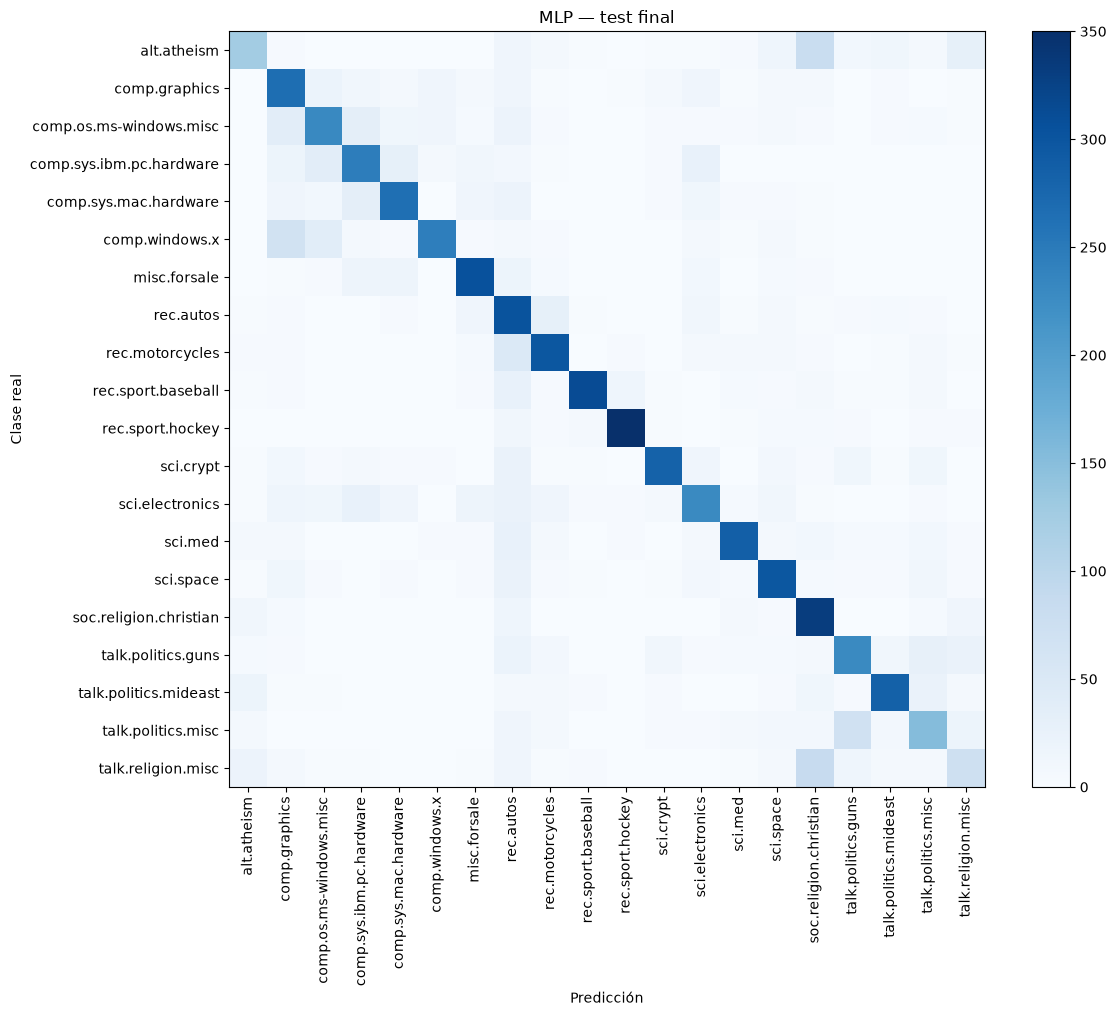

,real,predicha,cantidad,fraccion_de_clase_real
0,talk.religion.misc,soc.religion.christian,86,0.342629
1,alt.atheism,soc.religion.christian,81,0.253918
2,talk.politics.misc,talk.politics.guns,69,0.222581
3,comp.windows.x,comp.graphics,66,0.167089
4,rec.motorcycles,rec.autos,48,0.120603
5,comp.windows.x,comp.os.ms-windows.misc,38,0.096203
6,comp.os.ms-windows.misc,comp.graphics,36,0.091371
7,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,36,0.091837
8,comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware,34,0.086294
9,comp.sys.mac.hardware,comp.sys.ibm.pc.hardware,33,0.085714


,indice,real,predicha,texto
0,0,rec.autos,comp.sys.mac.hardware,I am a little confused on all of the models of...
1,1,comp.windows.x,comp.graphics,I'm not familiar at all with the format of the...
2,3,talk.politics.mideast,alt.atheism,\nThey were attacking the Iraqis to drive them...
3,4,talk.religion.misc,alt.atheism,\nI've just spent two solid months arguing tha...
4,6,soc.religion.christian,sci.space,"Dishonest money dwindles away, but he who gath..."
5,7,soc.religion.christian,sci.space,A friend of mine managed to get a copy of a co...


In [15]:
cm = confusion_matrix(truths, predictions, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm, cmap='Blues')
ax.set(xticks=np.arange(20), yticks=np.arange(20), xticklabels=class_names,
       yticklabels=class_names, xlabel='Predicción', ylabel='Clase real', title='MLP — test final')
plt.setp(ax.get_xticklabels(), rotation=90)
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
confusions = []
for position in np.argsort(off_diagonal.ravel())[::-1][:10]:
    actual, predicted = np.unravel_index(position, cm.shape)
    confusions.append({'real': class_names[actual], 'predicha': class_names[predicted],
                       'cantidad': int(cm[actual, predicted]),
                       'fraccion_de_clase_real': float(cm[actual, predicted] / cm[actual].sum())})
display(pd.DataFrame(confusions))
save_json(OUT / 'confusiones.json', confusions)
error_indices = np.flatnonzero(predictions != truths)
error_examples = [{'indice': int(i), 'real': class_names[truths[i]],
                   'predicha': class_names[predictions[i]],
                   'texto': newsgroups_test.data[i][:900]} for i in error_indices[:6]]
display(pd.DataFrame(error_examples))


In [16]:
def summary_row(record):
    config, history = record['config'], record['history']
    row = {'entrenamiento': record['name'], 'fase': record['phase'], 'estado': record['state'],
           'epocas': len(history), 'D': record['input_dim'], 'parametros': record['parameters'],
           'ocultas': str(hidden_sizes(config)), 'activacion': config['activation'],
           'optimizador': config['optimizer'], 'lr': config['lr'], 'batch': config['batch_size'],
           'ajuste_s': record['update_sec'], 'ciclo_s': record['cycle_sec'],
           'preparacion_datos_s': record['data_info'].get('preparation_sec', 0.),
           'preparacion_compartida': record['data_info'].get('shared_representation', False),
           'preparacion_modelo_s': record['model_setup_sec'],
           'pasos': sum(h['updates'] for h in history),
           'train_acc': history[-1]['train_fixed_acc'] if history else np.nan,
           'val_acc': history[-1].get('val_acc', np.nan) if history else np.nan,
           'val_loss': history[-1].get('val_loss', np.nan) if history else np.nan,
           'configuracion_completa': json.dumps(config, ensure_ascii=False)}
    val_history = [h for h in history if 'val_acc' in h]
    if val_history:
        own_target = 0.95 * max(h['val_acc'] for h in val_history)
        row['tiempo_95pct_techo_observado_s'] = next(
            h['cumulative_cycle_sec'] for h in val_history if h['val_acc'] >= own_target)
        reached = [h['cumulative_cycle_sec'] for h in val_history if h['val_acc'] >= 0.70]
        row['tiempo_accuracy_070_s'] = reached[0] if reached else np.nan
    return row

all_results = pd.DataFrame([summary_row(r) for r in RECORDS])
all_results.to_csv(OUT / 'todos_los_entrenamientos.csv', index=False)
save_json(OUT / 'todos_los_entrenamientos.json', RECORDS)
with pd.option_context('display.max_rows', 100, 'display.max_columns', None):
    display(all_results[['entrenamiento', 'fase', 'estado', 'epocas', 'ocultas', 'activacion',
                         'optimizador', 'D', 'parametros', 'train_acc', 'val_acc', 'ajuste_s', 'ciclo_s']])
display(all_results[['entrenamiento', 'lr', 'batch', 'pasos', 'preparacion_datos_s',
                     'preparacion_compartida', 'preparacion_modelo_s',
                     'tiempo_95pct_techo_observado_s', 'tiempo_accuracy_070_s']])
with pd.option_context('display.max_colwidth', None):
    display(all_results[['entrenamiento', 'configuracion_completa']])


,entrenamiento,fase,estado,epocas,ocultas,activacion,optimizador,D,parametros,train_acc,val_acc,ajuste_s,ciclo_s
0,trial_00,search,COMPLETE,8,[64],relu,Adam,5000,321364,0.968622,0.701281,6.236652,10.693556
1,trial_01,search,COMPLETE,8,"[64, 32]",tanh,RMSprop,2000,130804,0.809524,0.574017,6.843199,11.223052
2,trial_02,search,COMPLETE,8,"[128, 64, 32]",sigmoid,SGD,9330,1205364,0.052591,0.052585,19.170759,31.340747
3,trial_03,search,COMPLETE,8,"[32, 64, 128]",relu,Adam,10000,333044,0.962656,0.593460,12.435707,18.852224
4,trial_04,search,COMPLETE,8,[128],tanh,RMSprop,5000,642708,0.971716,0.646045,19.317923,27.596788
5,trial_05,search,COMPLETE,8,"[32, 64]",sigmoid,SGD,2000,67444,0.052149,0.052143,4.086356,7.795910
6,trial_06,search,PRUNED,4,"[128, 64, 32]",sigmoid,SGD,2000,267124,0.052259,0.052143,2.744770,4.979246
7,trial_07,search,PRUNED,4,"[64, 64, 64]",sigmoid,Adam,10000,649684,0.789195,0.551038,11.840921,16.526213
8,trial_08,search,PRUNED,4,"[32, 128, 128]",relu,RMSprop,2000,87348,0.855265,0.570924,3.927316,6.273147
9,trial_09,search,PRUNED,4,"[32, 32]",tanh,SGD,5000,161748,0.095680,0.095890,4.871934,8.271254


,entrenamiento,lr,batch,pasos,preparacion_datos_s,preparacion_compartida,preparacion_modelo_s,tiempo_95pct_techo_observado_s,tiempo_accuracy_070_s
0,trial_00,0.003000,128,568,2.524403,False,0.018184,2.680736,2.680736
1,trial_01,0.001000,64,1136,10.935495,False,0.004971,4.220080,NaN
2,trial_02,0.100000,32,2264,2.247992,False,0.060243,3.852979,NaN
3,trial_03,0.010000,64,1136,10.265950,False,0.014986,2.461478,NaN
4,trial_04,0.001000,32,2264,2.546895,False,0.033981,3.516210,NaN
5,trial_05,0.100000,128,568,9.425048,False,0.004772,4.878421,NaN
6,trial_06,0.061401,128,284,2.168034,False,0.016453,1.355126,NaN
7,trial_07,0.002187,32,1132,10.082934,False,0.032406,16.526213,NaN
8,trial_08,0.001538,64,568,2.049300,False,0.008497,1.499150,NaN
9,trial_09,0.008565,32,1132,2.116659,False,0.010834,8.271254,NaN


,entrenamiento,configuracion_completa
0,trial_00,"{""remove_stopwords"": true, ""normalization"": ""lemmatize"", ""ngram_range"": ""1gram"", ""max_features"": 5000, ""min_df"": 2, ""lr"": 0.003, ""batch_size"": 128, ""n_layers"": 1, ""activation"": ""relu"", ""optimizer"": ""Adam"", ""h1"": 64, ""beta1"": 0.9, ""beta2"": 0.999}"
1,trial_01,"{""remove_stopwords"": false, ""normalization"": ""none"", ""ngram_range"": ""1_2gram"", ""max_features"": 2000, ""min_df"": 1, ""lr"": 0.001, ""batch_size"": 64, ""n_layers"": 2, ""activation"": ""tanh"", ""optimizer"": ""RMSprop"", ""h1"": 64, ""h2"": 32, ""alpha"": 0.9, ""rms_momentum"": 0.0}"
2,trial_02,"{""remove_stopwords"": true, ""normalization"": ""stem"", ""ngram_range"": ""1gram"", ""max_features"": 10000, ""min_df"": 5, ""lr"": 0.1, ""batch_size"": 32, ""n_layers"": 3, ""activation"": ""sigmoid"", ""optimizer"": ""SGD"", ""h1"": 128, ""h2"": 64, ""h3"": 32, ""sgd_momentum"": 0.0}"
3,trial_03,"{""remove_stopwords"": false, ""normalization"": ""lemmatize"", ""ngram_range"": ""1_2gram"", ""max_features"": 10000, ""min_df"": 1, ""lr"": 0.01, ""batch_size"": 64, ""n_layers"": 3, ""activation"": ""relu"", ""optimizer"": ""Adam"", ""h1"": 32, ""h2"": 64, ""h3"": 128, ""beta1"": 0.8, ""beta2"": 0.99}"
4,trial_04,"{""remove_stopwords"": true, ""normalization"": ""none"", ""ngram_range"": ""1gram"", ""max_features"": 5000, ""min_df"": 5, ""lr"": 0.001, ""batch_size"": 32, ""n_layers"": 1, ""activation"": ""tanh"", ""optimizer"": ""RMSprop"", ""h1"": 128, ""alpha"": 0.99, ""rms_momentum"": 0.9}"
5,trial_05,"{""remove_stopwords"": false, ""normalization"": ""stem"", ""ngram_range"": ""1_2gram"", ""max_features"": 2000, ""min_df"": 2, ""lr"": 0.1, ""batch_size"": 128, ""n_layers"": 2, ""activation"": ""sigmoid"", ""optimizer"": ""SGD"", ""h1"": 32, ""h2"": 64, ""sgd_momentum"": 0.9}"
6,trial_06,"{""remove_stopwords"": true, ""normalization"": ""none"", ""ngram_range"": ""1gram"", ""max_features"": 2000, ""min_df"": 2, ""lr"": 0.06140120892551821, ""batch_size"": 128, ""n_layers"": 3, ""activation"": ""sigmoid"", ""optimizer"": ""SGD"", ""h1"": 128, ""h2"": 64, ""h3"": 32, ""sgd_momentum"": 0.9}"
7,trial_07,"{""remove_stopwords"": false, ""normalization"": ""stem"", ""ngram_range"": ""1_2gram"", ""max_features"": 10000, ""min_df"": 2, ""lr"": 0.002187354031740165, ""batch_size"": 32, ""n_layers"": 3, ""activation"": ""sigmoid"", ""optimizer"": ""Adam"", ""h1"": 64, ""h2"": 64, ""h3"": 64, ""beta1"": 0.8, ""beta2"": 0.999}"
8,trial_08,"{""remove_stopwords"": true, ""normalization"": ""none"", ""ngram_range"": ""1gram"", ""max_features"": 2000, ""min_df"": 5, ""lr"": 0.0015380932295208176, ""batch_size"": 64, ""n_layers"": 3, ""activation"": ""relu"", ""optimizer"": ""RMSprop"", ""h1"": 32, ""h2"": 128, ""h3"": 128, ""alpha"": 0.9, ""rms_momentum"": 0.9}"
9,trial_09,"{""remove_stopwords"": true, ""normalization"": ""stem"", ""ngram_range"": ""1gram"", ""max_features"": 5000, ""min_df"": 1, ""lr"": 0.008564724527675207, ""batch_size"": 32, ""n_layers"": 2, ""activation"": ""tanh"", ""optimizer"": ""SGD"", ""h1"": 32, ""h2"": 32, ""sgd_momentum"": 0.0}"


La tabla incluye todas las corridas TNG, también podadas y fallidas si las hubo.
Para cada una, el JSON/MLflow conserva los parámetros y curvas completos.
`preparacion_compartida=True` indica que las comparaciones reutilizan una matriz:
no sumar ese costo repetidamente. El preprocesamiento lingüístico global se mide
aparte, una vez por variante. El ciclo incluye ajuste/evaluación/logging de
métricas; excluye descargar, instalar, preparar datos/modelo, persistir JSON,
imprimir y abrir/cerrar la corrida. Los tiempos no son benchmarks de hardware.

Tiempo al 95 % del mejor accuracy observado de cada caso aproxima su propio
techo dentro del presupuesto: una red mala puede alcanzarlo pronto. No prueba
convergencia matemática. El tiempo hasta accuracy 0.70 permite comparar un mismo
umbral; NaN significa «no alcanzado». Las curvas contra segundos complementan
las curvas por época. No extrapolamos los trials podados hasta ocho épocas.


,entrenamiento,estado,epocas,val_acc,val_loss,ciclo_s,configuracion_completa
17,trial_17,COMPLETE,8,0.711887,1.383155,45.101800,"{""remove_stopwords"": true, ""normalization"": ""l..."
20,trial_20,COMPLETE,8,0.710561,1.184200,23.446784,"{""remove_stopwords"": true, ""normalization"": ""l..."
21,trial_21,COMPLETE,8,0.703049,1.287779,22.538090,"{""remove_stopwords"": true, ""normalization"": ""l..."
0,trial_00,COMPLETE,8,0.701281,1.040574,10.693556,"{""remove_stopwords"": true, ""normalization"": ""l..."
23,trial_23,COMPLETE,8,0.698630,1.716569,48.393278,"{""remove_stopwords"": true, ""normalization"": ""l..."
16,trial_16,COMPLETE,8,0.696421,1.136362,22.915686,"{""remove_stopwords"": true, ""normalization"": ""l..."
12,trial_12,COMPLETE,8,0.685373,1.230229,11.377457,"{""remove_stopwords"": true, ""normalization"": ""l..."
14,trial_14,COMPLETE,8,0.683164,1.228580,8.821906,"{""remove_stopwords"": true, ""normalization"": ""l..."
15,trial_15,COMPLETE,8,0.663721,1.428810,18.506108,"{""remove_stopwords"": true, ""normalization"": ""n..."
13,trial_13,COMPLETE,8,0.650022,1.756046,12.256470,"{""remove_stopwords"": true, ""normalization"": ""l..."


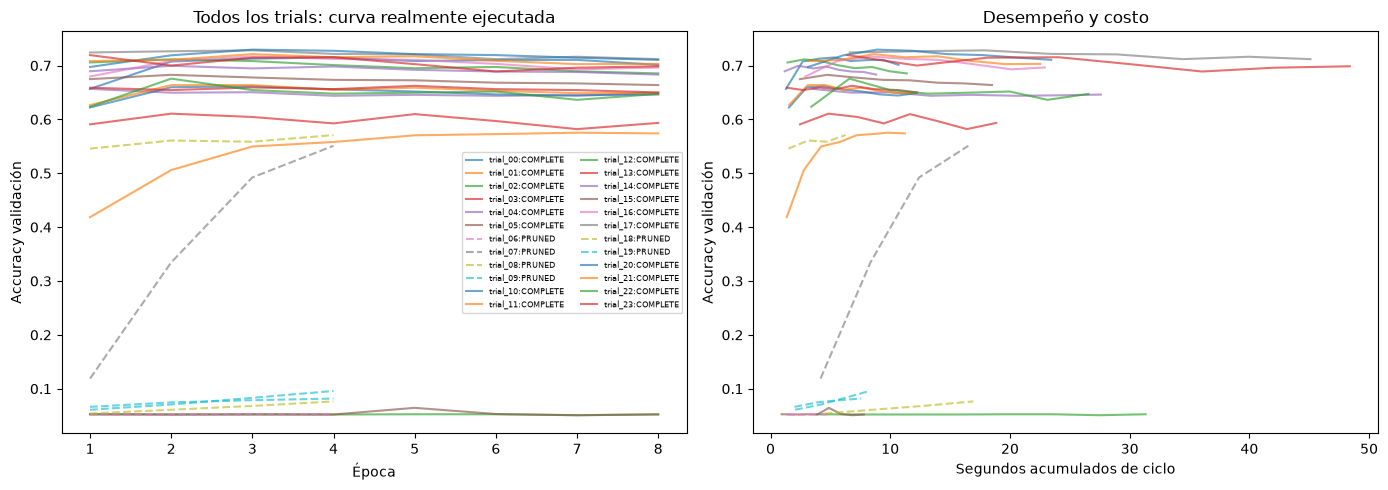

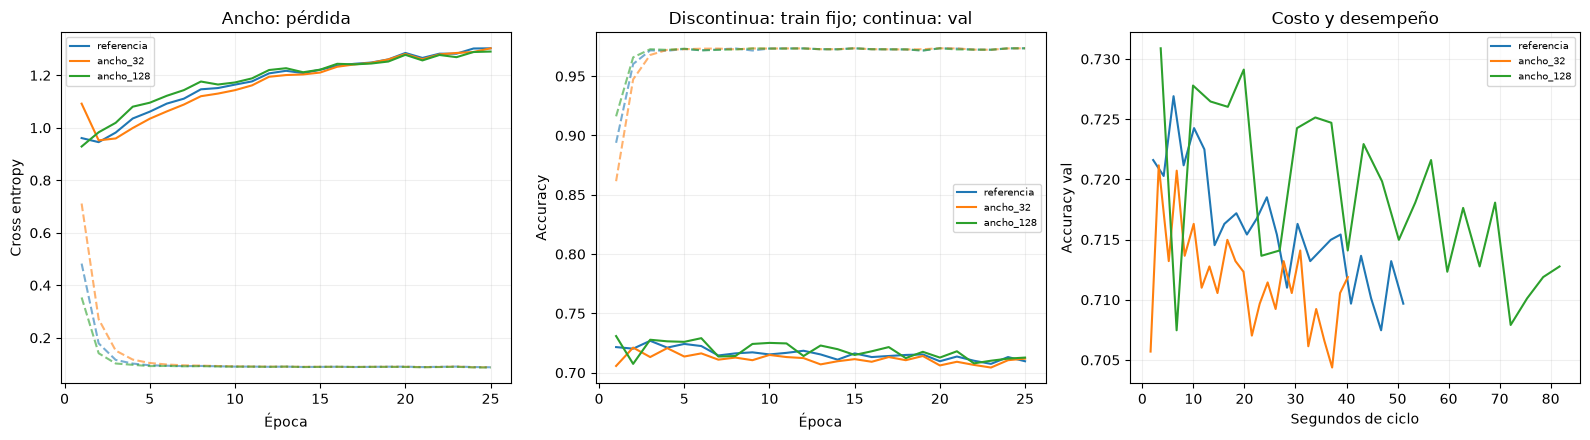

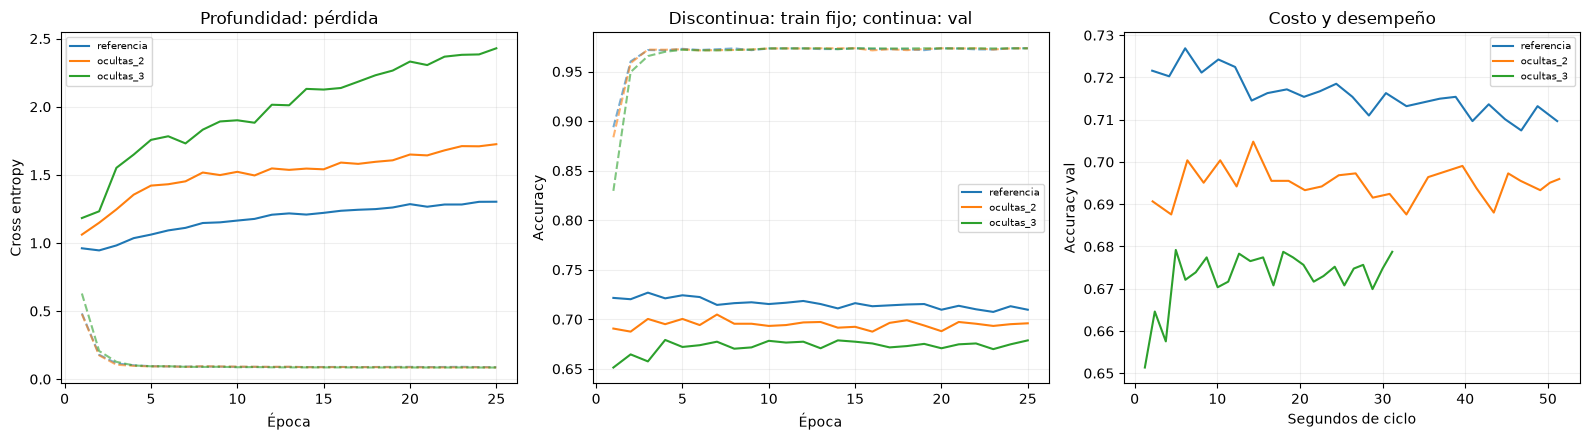

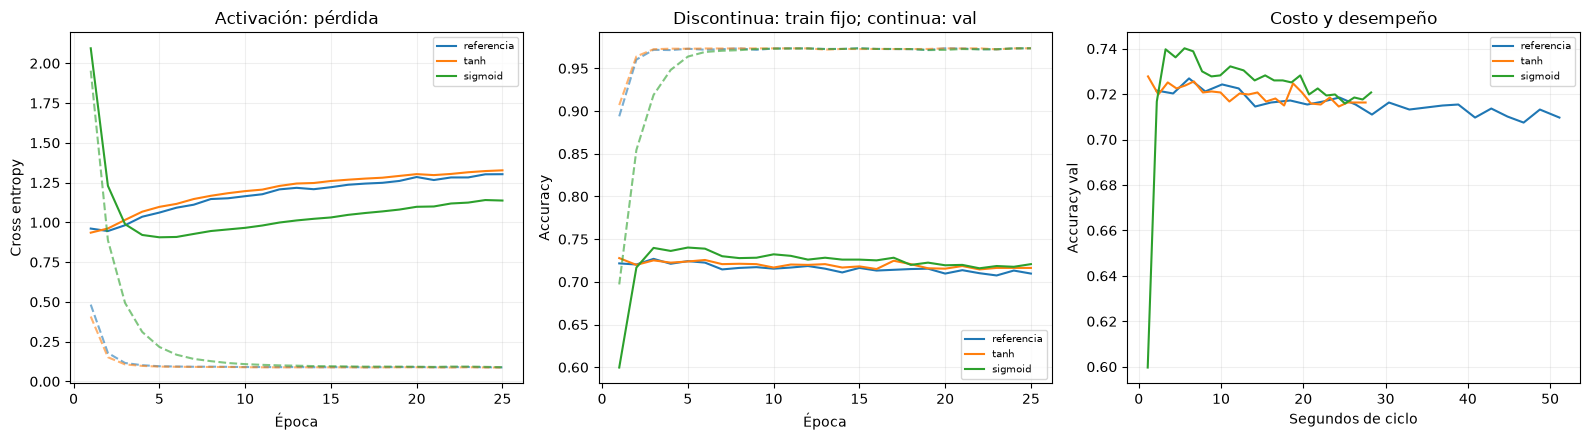

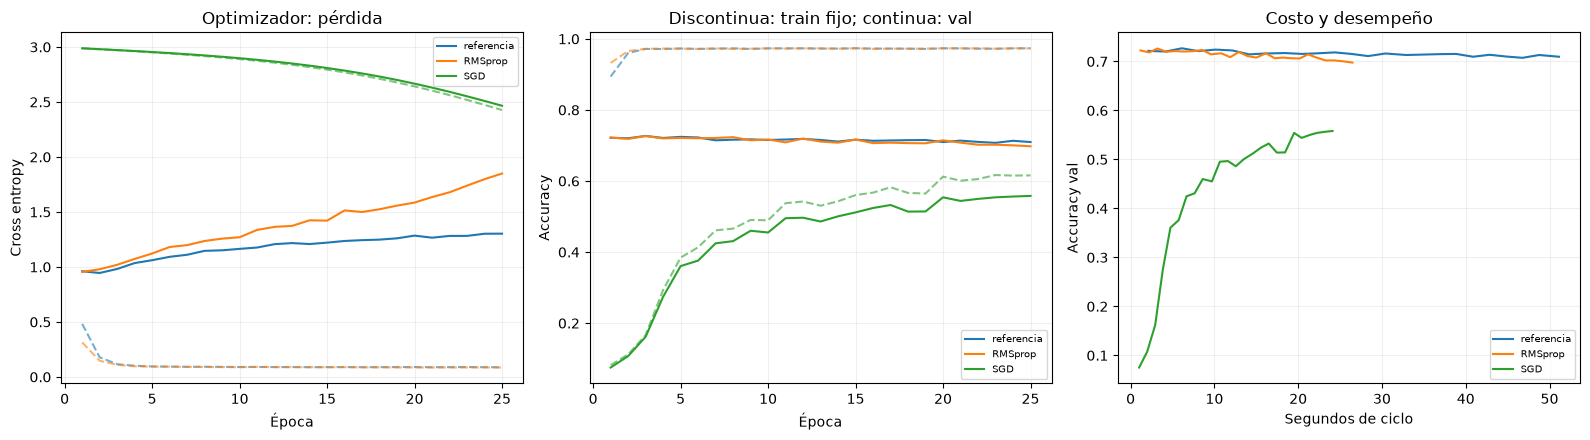

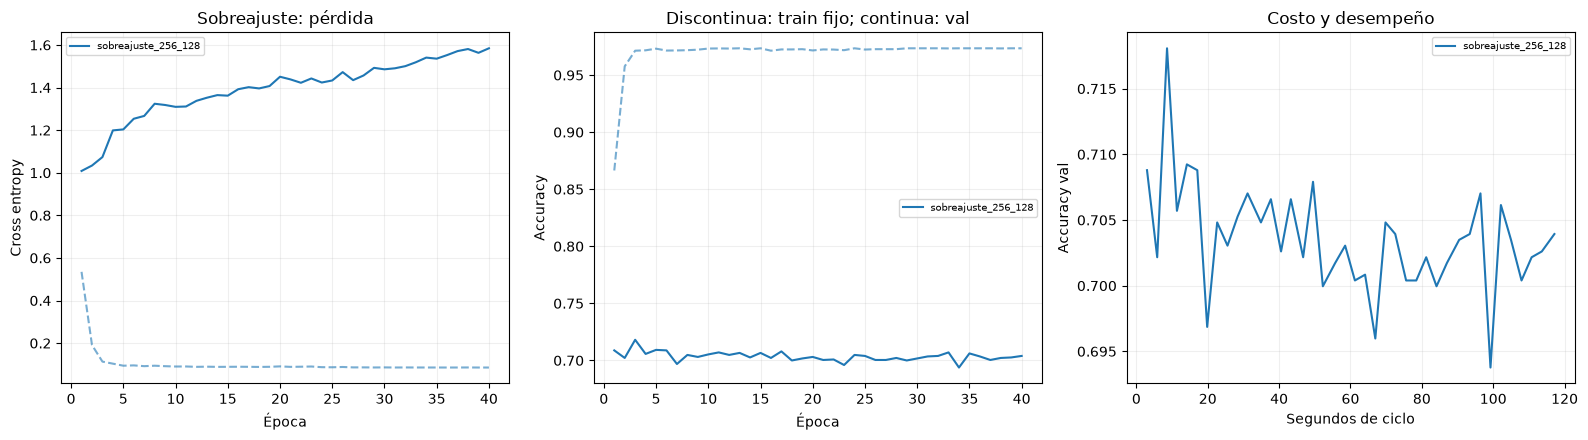

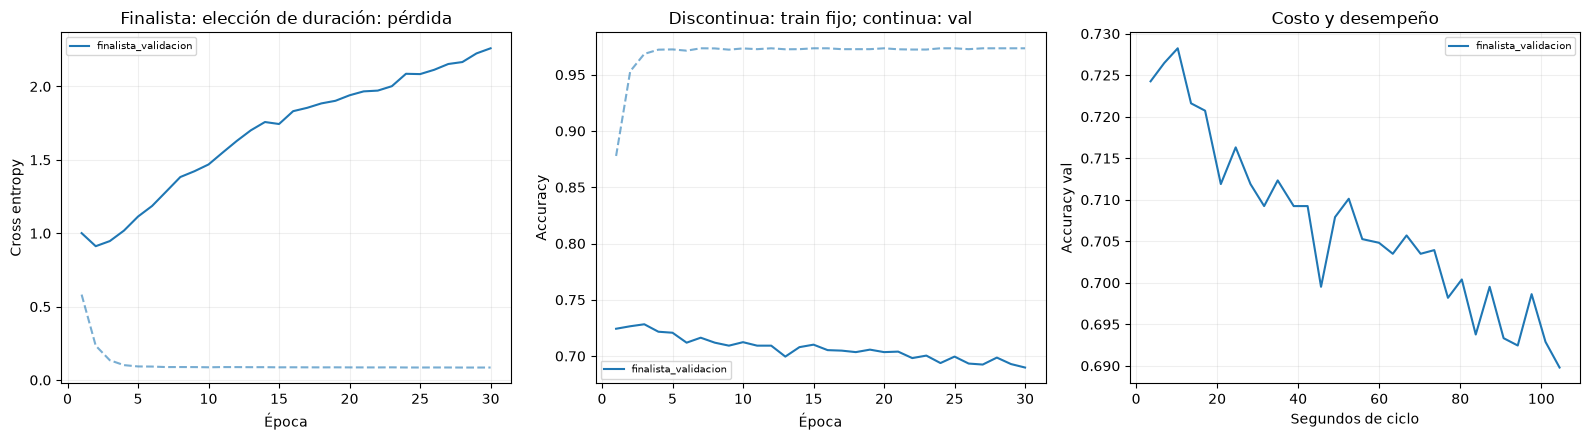

In [17]:
search_df = all_results[all_results['fase'] == 'search'].copy()
display(search_df.sort_values(['estado', 'val_acc'], ascending=[True, False])[
    ['entrenamiento', 'estado', 'epocas', 'val_acc', 'val_loss', 'ciclo_s', 'configuracion_completa']])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for r in search_records:
    h = pd.DataFrame(r['history'])
    if h.empty:
        continue
    style = '--' if r['state'] == 'PRUNED' else '-'
    axes[0].plot(h['epoch'], h['val_acc'], style, alpha=0.65, label=r['name'] + ':' + r['state'])
    axes[1].plot(h['cumulative_cycle_sec'], h['val_acc'], style, alpha=0.65)
axes[0].set(xlabel='Época', ylabel='Accuracy validación', title='Todos los trials: curva realmente ejecutada')
axes[1].set(xlabel='Segundos acumulados de ciclo', ylabel='Accuracy validación', title='Desempeño y costo')
axes[0].legend(fontsize=6, ncol=2)
fig.tight_layout()
plt.show()

def plot_group(records, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for index, r in enumerate(records):
        h = pd.DataFrame(r['history'])
        label = r['name'].replace('comparacion_', '')
        color = f'C{index % 10}'
        axes[0].plot(h['epoch'], h['train_fixed_loss'], '--', color=color, alpha=0.6)
        axes[0].plot(h['epoch'], h['val_loss'], color=color, label=label)
        axes[1].plot(h['epoch'], h['train_fixed_acc'], '--', color=color, alpha=0.6)
        axes[1].plot(h['epoch'], h['val_acc'], color=color, label=label)
        axes[2].plot(h['cumulative_cycle_sec'], h['val_acc'], color=color, label=label)
    axes[0].set(xlabel='Época', ylabel='Cross entropy', title=title + ': pérdida')
    axes[1].set(xlabel='Época', ylabel='Accuracy', title='Discontinua: train fijo; continua: val')
    axes[2].set(xlabel='Segundos de ciclo', ylabel='Accuracy val', title='Costo y desempeño')
    for ax in axes:
        ax.legend(fontsize=7)
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

for title, names in [
    ('Ancho', ['referencia', 'ancho_32', 'ancho_128']),
    ('Profundidad', ['referencia', 'ocultas_2', 'ocultas_3']),
    ('Activación', ['referencia', 'tanh', 'sigmoid']),
    ('Optimizador', ['referencia', 'RMSprop', 'SGD'])]:
    plot_group([r for r in comparison_records if r['name'] in ['comparacion_' + n for n in names]], title)
plot_group(overfit_records, 'Sobreajuste')
plot_group([finalist_record], 'Finalista: elección de duración')


### Lectura de los resultados de esta ejecución
El texto siguiente se calcula a partir de los mismos historiales que las tablas
y figuras. Separa observaciones numéricas de interpretaciones y evita conservar
conclusiones de una corrida anterior al volver a ejecutar el notebook.


In [18]:
complete_search = search_df[search_df['estado'] == 'COMPLETE'].sort_values('val_acc', ascending=False)
states = search_df['estado'].value_counts().to_dict()
worst = complete_search.iloc[-1]
winner = complete_search.iloc[0]
worst_record = next(r for r in search_records if r['name'] == worst['entrenamiento'])
worst_history = worst_record['history']
pruned_epochs = int(search_df.loc[search_df['estado'] == 'PRUNED', 'epocas'].sum())
pruned_count = states.get('PRUNED', 0)
comparison_table = all_results[all_results['fase'] == 'comparison'].set_index('entrenamiento')
reference = comparison_table.loc['comparacion_referencia']
# Diagnóstico de la representación, sin entrenar ni consultar test: textos distintos
# que quedan en el vector cero reciben necesariamente la misma predicción.
_processed = preprocessed_cache[best['remove_stopwords'], best['normalization']]
_x_diagnostic, _, _ = vectorize_data(
    [_processed[i] for i in train_idx], [''],
    (1, 1) if best['ngram_range'] == '1gram' else (1, 2), best['max_features'], best['min_df'])
_zero_mask = np.asarray(_x_diagnostic.getnnz(axis=1) == 0)
_zero_count = int(_zero_mask.sum())
_zero_classes = np.bincount(labels[train_idx][_zero_mask], minlength=20)
_zero_max_correct = int(_zero_classes.max())
_train_upper_bound = (len(train_idx) - _zero_count + _zero_max_correct) / len(train_idx)
zero_diagnosis = {'zero_train_vectors': _zero_count, 'zero_label_counts': _zero_classes.tolist(),
                  'most_frequent_zero_class_count': _zero_max_correct,
                  'train_accuracy_upper_bound_due_to_zero_vectors': _train_upper_bound}
(OUT / 'diagnostico_vectores_nulos.json').write_text(json.dumps(zero_diagnosis, indent=2), encoding='utf-8')
del _x_diagnostic, _processed
lines = [
    f'**Búsqueda.** Se ejecutaron {len(search_df)} trials: {states}. El mejor completo fue '
    f'{winner["entrenamiento"]}, con accuracy de validación {winner["val_acc"]:.4f} al terminar '
    f'{SEARCH_EPOCHS} épocas. El peor completo, {worst["entrenamiento"]}, obtuvo {worst["val_acc"]:.4f}. '
    'Esta amplitud muestra que arquitectura, texto y entrenamiento deben evaluarse conjuntamente; '
    'no permite atribuir la diferencia a un único HP.',
    f'**Caso con poco aprendizaje.** {worst["entrenamiento"]} terminó con '
    f'train accuracy={worst_history[-1]["train_fixed_acc"]:.4f}, '
    f'val accuracy={worst_history[-1]["val_acc"]:.4f}, '
    f'train loss={worst_history[-1]["train_fixed_loss"]:.4f} y '
    f'val loss={worst_history[-1]["val_loss"]:.4f}. Como referencia, predecir '
    f'probabilidades uniformes produce cross entropy ln(20)={np.log(20):.4f}. '
    'La proximidad al nivel uniforme, cuando se observa, indica falta de aprendizaje '
    'útil en ese presupuesto; no demuestra por sí sola que falte capacidad. '
    f'La configuración concreta fue `{json.dumps(worst_record["config"], ensure_ascii=False)}`.',
    f'**Límite de la representación.** En train interno, {_zero_count} documentos quedaron '
    f'como vectores TF-IDF nulos; la clase más frecuente entre ellos tiene {_zero_max_correct} '
    f'ejemplos. Una red determinista predice lo mismo para todos esos vectores idénticos. '
    f'Aun acertando todos los otros documentos, su accuracy train no podría superar '
    f'{_train_upper_bound:.6f} debido a ese grupo. La referencia alcanzó '
    f'{reference["train_acc"]:.6f}. Este límite permite interpretar la meseta sin exigir '
    '100 % de train ni atribuir automáticamente el residuo a falta de capacidad. '
    'No se quitaron esos documentos ni se cambiaron etiquetas.',
    f'**Configuración seleccionada.** `{json.dumps(best, ensure_ascii=False)}`. '
    'La normalización lingüística cambia las formas que comparten características; los bigramas '
    'pueden conservar contexto local, a costa de ampliar el vocabulario. La elección observada '
    'es la ganadora del presupuesto ejecutado, no prueba que las alternativas sean inútiles.',
    f'**Pruning.** {pruned_count} trials podados ejecutaron {pruned_epochs} épocas; '
    f'se omitieron {pruned_count * SEARCH_EPOCHS - pruned_epochs} épocas respecto de completarlos. '
    'Es ahorro de épocas, no una medición contrafáctica de segundos: los costos por época varían. '
    'Los seis casos iniciales completos aseguran cobertura. La poda puede perjudicar a '
    'configuraciones de aprendizaje lento y no permite saber cómo habrían terminado.',
]
for title, cases in [('Ancho', ['ancho_32', 'ancho_128']),
                     ('Profundidad', ['ocultas_2', 'ocultas_3']),
                     ('Activación', ['tanh', 'sigmoid']),
                     ('Optimizador', ['RMSprop', 'SGD'])]:
    observations = []
    for case in cases:
        row = comparison_table.loc['comparacion_' + case]
        observations.append(f'{case}: val={row["val_acc"]:.4f}, diferencia '
                            f'{100 * (row["val_acc"] - reference["val_acc"]):+.2f} puntos, '
                            f'{row["parametros"]:,} parámetros y {row["ciclo_s"]:.1f} s de ciclo')
    lines.append(f'**{title}.** Referencia val={reference["val_acc"]:.4f}, '
                 f'{reference["ciclo_s"]:.1f} s. ' + '; '.join(observations) +
                 '. Comparación a 25 épocas, misma representación/split/inicializador y una semilla. '
                 'La diferencia corresponde a estas condiciones.' +
                 (' En los optimizadores el LR es común y no se optimizó por familia.'
                  if title == 'Optimizador' else ''))
for r in overfit_records:
    d = r['overfit_diagnosis']
    lines.append(f'**Capacidad y sobreajuste ({hidden_sizes(r["config"])}).** '
                 f'Brecha final train–val: {100*d["accuracy_gap"]:.2f} puntos. '
                 f'Train loss media inicial/final: {d["train_loss_first5"]:.4f}/'
                 f'{d["train_loss_last5"]:.4f}; val loss final/mínimo móvil: '
                 f'{d["val_loss_last5"]:.4f}/{d["min_rolling5_val_loss"]:.4f}. '
                 f'Cumple el diagnóstico fijado: {d["demonstrated"]}. '
                 'La reducción de error de entrenamiento acompañada por deterioro de validación '
                 'respalda sobreajuste cuando se cumple el criterio; no demuestra que toda red ancha '
                 'generalice peor. Parada temprana o regularización serían alternativas a estudiar.')
_ref = next(r for r in comparison_records if r['name'] == 'comparacion_referencia')
_ref_min_loss = min(_ref['history'], key=lambda h: h['val_loss'])
_sigmoid = next(r for r in comparison_records if r['name'] == 'comparacion_sigmoid')
_sigmoid_peak = max(_sigmoid['history'], key=lambda h: h['val_acc'])
_sgd = next(r for r in comparison_records if r['name'] == 'comparacion_SGD')
lines.append(
    f'**Dinámica de los casos controlados.** La referencia tuvo su mínima pérdida de '
    f'validación en la época {_ref_min_loss["epoch"]} ({_ref_min_loss["val_loss"]:.4f}), '
    f'frente a {_ref["history"][-1]["val_loss"]:.4f} al terminar; prolongar el ajuste '
    'redujo train loss pero deterioró validación. Sigmoid con Adam sí aprendió en la '
    f'comparación de una oculta: llegó a val accuracy={_sigmoid_peak["val_acc"]:.4f} en '
    f'la época {_sigmoid_peak["epoch"]}. Por eso los trials malos que combinaron '
    'sigmoid, profundidad y otro optimizador no prueban que sigmoid sea siempre peor. '
    f'SGD terminó con train loss={_sgd["history"][-1]["train_fixed_loss"]:.4f} '
    f'(inicial {_sgd["history"][0]["train_fixed_loss"]:.4f}), lejos del ajuste de Adam. '
    'Sus curvas aún muestran aprendizaje dentro del presupuesto; el resultado a 25 '
    'épocas con LR=0.01 no representa su desempeño después de una convergencia demostrada.')
lines.extend([
    '**Confusiones observadas.** Las tres confusiones dirigidas más numerosas fueron: ' +
    '; '.join(f'{c["real"]} → {c["predicha"]}: {c["cantidad"]} textos '
              f'({100*c["fraccion_de_clase_real"]:.1f} % de la clase real)'
              for c in confusions[:3]) + '. Los ejemplos de errores se muestran arriba. '
    'Compartir vocabulario temático o perder contexto al vectorizar son hipótesis que '
    'deben contrastarse con esos textos; el conteo por sí solo no prueba la causa.',
    f'**Modelo final.** La mínima pérdida del finalista eligió {selected_epochs} épocas; '
    f'otro entrenamiento con todo el train oficial obtuvo accuracy test={test_accuracy:.4f} '
    f'y F1 macro={test_f1_macro:.4f}. El reajuste del vocabulario y el mayor número de documentos '
    'hacen que el entrenamiento final no sea una continuación del trial ganador.',
    '**Tiempos y límites.** Las curvas por segundos y los umbrales de la tabla permiten distinguir '
    'aprendizaje rápido de mejor desempeño final. Una meseta de accuracy no prueba convergencia de '
    'la pérdida. Con validación, el ciclo incluye evaluar train y validación; en el ajuste final '
    'solo se evalúa train durante las épocas. Datos compartidos, carga del equipo y una sola '
    'semilla limitan la generalización de los tiempos. '
    'No se declara una mejora estadísticamente significativa ni un óptimo global.',
])
analysis_text = '\n\n'.join(lines)
display(Markdown(analysis_text))
(OUT / 'analisis.md').write_text(analysis_text, encoding='utf-8')


**Búsqueda.** Se ejecutaron 24 trials: {'COMPLETE': 18, 'PRUNED': 6}. El mejor completo fue trial_17, con accuracy de validación 0.7119 al terminar 8 épocas. El peor completo, trial_05, obtuvo 0.0521. Esta amplitud muestra que arquitectura, texto y entrenamiento deben evaluarse conjuntamente; no permite atribuir la diferencia a un único HP.

**Caso con poco aprendizaje.** trial_05 terminó con train accuracy=0.0521, val accuracy=0.0521, train loss=2.9941 y val loss=2.9942. Como referencia, predecir probabilidades uniformes produce cross entropy ln(20)=2.9957. La proximidad al nivel uniforme, cuando se observa, indica falta de aprendizaje útil en ese presupuesto; no demuestra por sí sola que falte capacidad. La configuración concreta fue `{"remove_stopwords": false, "normalization": "stem", "ngram_range": "1_2gram", "max_features": 2000, "min_df": 2, "lr": 0.1, "batch_size": 128, "n_layers": 2, "activation": "sigmoid", "optimizer": "SGD", "h1": 32, "h2": 64, "sgd_momentum": 0.9}`.

**Límite de la representación.** En train interno, 261 documentos quedaron como vectores TF-IDF nulos; la clase más frecuente entre ellos tiene 30 ejemplos. Una red determinista predice lo mismo para todos esos vectores idénticos. Aun acertando todos los otros documentos, su accuracy train no podría superar 0.974478 debido a ese grupo. La referencia alcanzó 0.973484. Este límite permite interpretar la meseta sin exigir 100 % de train ni atribuir automáticamente el residuo a falta de capacidad. No se quitaron esos documentos ni se cambiaron etiquetas.

**Configuración seleccionada.** `{"remove_stopwords": true, "normalization": "lemmatize", "ngram_range": "1gram", "max_features": 10000, "min_df": 2, "lr": 0.0027282596831844034, "batch_size": 32, "n_layers": 1, "activation": "relu", "optimizer": "Adam", "h1": 128, "beta1": 0.9, "beta2": 0.99}`. La normalización lingüística cambia las formas que comparten características; los bigramas pueden conservar contexto local, a costa de ampliar el vocabulario. La elección observada es la ganadora del presupuesto ejecutado, no prueba que las alternativas sean inútiles.

**Pruning.** 6 trials podados ejecutaron 24 épocas; se omitieron 24 épocas respecto de completarlos. Es ahorro de épocas, no una medición contrafáctica de segundos: los costos por época varían. Los seis casos iniciales completos aseguran cobertura. La poda puede perjudicar a configuraciones de aprendizaje lento y no permite saber cómo habrían terminado.

**Ancho.** Referencia val=0.7097, 51.1 s. ancho_32: val=0.7119, diferencia +0.22 puntos, 320,692 parámetros y 40.3 s de ciclo; ancho_128: val=0.7128, diferencia +0.31 puntos, 1,282,708 parámetros y 81.7 s de ciclo. Comparación a 25 épocas, misma representación/split/inicializador y una semilla. La diferencia corresponde a estas condiciones.

**Profundidad.** Referencia val=0.7097, 51.1 s. ocultas_2: val=0.6960, diferencia -1.37 puntos, 645,524 parámetros y 51.4 s de ciclo; ocultas_3: val=0.6787, diferencia -3.09 puntos, 649,684 parámetros y 31.2 s de ciclo. Comparación a 25 épocas, misma representación/split/inicializador y una semilla. La diferencia corresponde a estas condiciones.

**Activación.** Referencia val=0.7097, 51.1 s. tanh: val=0.7163, diferencia +0.66 puntos, 641,364 parámetros y 27.6 s de ciclo; sigmoid: val=0.7207, diferencia +1.10 puntos, 641,364 parámetros y 28.2 s de ciclo. Comparación a 25 épocas, misma representación/split/inicializador y una semilla. La diferencia corresponde a estas condiciones.

**Optimizador.** Referencia val=0.7097, 51.1 s. RMSprop: val=0.6977, diferencia -1.19 puntos, 641,364 parámetros y 26.5 s de ciclo; SGD: val=0.5581, diferencia -15.16 puntos, 641,364 parámetros y 24.1 s de ciclo. Comparación a 25 épocas, misma representación/split/inicializador y una semilla. La diferencia corresponde a estas condiciones. En los optimizadores el LR es común y no se optimizó por familia.

**Capacidad y sobreajuste ([256, 128]).** Brecha final train–val: 26.96 puntos. Train loss media inicial/final: 0.2074/0.0855; val loss final/mínimo móvil: 1.5705/1.1037. Cumple el diagnóstico fijado: True. La reducción de error de entrenamiento acompañada por deterioro de validación respalda sobreajuste cuando se cumple el criterio; no demuestra que toda red ancha generalice peor. Parada temprana o regularización serían alternativas a estudiar.

**Dinámica de los casos controlados.** La referencia tuvo su mínima pérdida de validación en la época 2 (0.9453), frente a 1.3027 al terminar; prolongar el ajuste redujo train loss pero deterioró validación. Sigmoid con Adam sí aprendió en la comparación de una oculta: llegó a val accuracy=0.7402 en la época 5. Por eso los trials malos que combinaron sigmoid, profundidad y otro optimizador no prueban que sigmoid sea siempre peor. SGD terminó con train loss=2.4264 (inicial 2.9879), lejos del ajuste de Adam. Sus curvas aún muestran aprendizaje dentro del presupuesto; el resultado a 25 épocas con LR=0.01 no representa su desempeño después de una convergencia demostrada.

**Confusiones observadas.** Las tres confusiones dirigidas más numerosas fueron: talk.religion.misc → soc.religion.christian: 86 textos (34.3 % de la clase real); alt.atheism → soc.religion.christian: 81 textos (25.4 % de la clase real); talk.politics.misc → talk.politics.guns: 69 textos (22.3 % de la clase real). Los ejemplos de errores se muestran arriba. Compartir vocabulario temático o perder contexto al vectorizar son hipótesis que deben contrastarse con esos textos; el conteo por sí solo no prueba la causa.

**Modelo final.** La mínima pérdida del finalista eligió 2 épocas; otro entrenamiento con todo el train oficial obtuvo accuracy test=0.6782 y F1 macro=0.6681. El reajuste del vocabulario y el mayor número de documentos hacen que el entrenamiento final no sea una continuación del trial ganador.

**Tiempos y límites.** Las curvas por segundos y los umbrales de la tabla permiten distinguir aprendizaje rápido de mejor desempeño final. Una meseta de accuracy no prueba convergencia de la pérdida. Con validación, el ciclo incluye evaluar train y validación; en el ajuste final solo se evalúa train durante las épocas. Datos compartidos, carga del equipo y una sola semilla limitan la generalización de los tiempos. No se declara una mejora estadísticamente significativa ni un óptimo global.

6309

## 9. Preguntas de reflexión del punto de partida, aplicadas al MLP

**1. Softmax como generalización de regresión logística.** Extiende la decisión
binaria a C clases con logits y probabilidades que suman uno. Para dos clases,
la probabilidad depende de la diferencia entre ambos logits y equivale a una
sigmoid sobre esa diferencia. Aquí C=20; la última capa del MLP sigue esa salida.

**2. CrossEntropyLoss.** Recibe logits y etiquetas enteras, combinando log-softmax
y pérdida logarítmica de forma estable. Softmax previo fuerza a interpretarlas
como nuevos logits y altera valores y gradientes. Para inferir una etiqueta basta
argmax de logits; no hace falta convertirlos a probabilidades.

**3–4. Fronteras y ocultas.** Softmax lineal separa pares de clases mediante
hiperplanos en TF-IDF. Las activaciones permiten fronteras no lineales en la
representación original, aumentando capacidad y costo. Si el problema ya se
resuelve bien linealmente, su simplicidad puede ser ventajosa; el MLP necesita
evidencia de validación que justifique su complejidad. No afirmamos que supere
la entrega anterior, porque no se ejecutó un baseline lineal bajo este protocolo.

**5. PyTorch y scikit-learn.** PyTorch expone capas, forward, gradientes, batches
y optimizadores, útil para la búsqueda MLP y estudiar dinámica. Exige implementar
y verificar el ciclo y las métricas. LogisticRegression de scikit-learn ofrece
un clasificador lineal con entrenamiento encapsulado; no sustituye las ocultas
requeridas aquí. Las dos herramientas pueden aplicar pérdidas multinomiales,
pero sus solvers y convenciones de regularización no son automáticamente iguales.

**6. MLflow y TensorBoard.** MLflow identifica corridas y guarda parámetros,
métricas por época, tiempos, historiales y modelo final. TensorBoard registra
series temporales para comparar visualmente curvas. Se complementan y apuntan
a esta ejecución. El notebook muestra resultados sin exigir abrir sus interfaces.

**7. Optuna.** Evita escribir manualmente todo el producto cartesiano; TPE usa
los resultados anteriores para proponer pruebas y permite espacios condicionales.
Encolamos seis casos para asegurar cobertura e incorporamos poda. Una búsqueda
corta y adaptativa puede perder configuraciones buenas: no prueba optimalidad.

**8. Preprocesamiento ganador.** La sección de resultados imprime la combinación
exacta de esta ejecución. Compartir raíces o lemas puede reducir dispersión;
stopwords y bigramas también pueden conservar o quitar señales útiles. Es una
interpretación posible del resultado conjunto, no una ablación de cada factor.

**9–10. Confusiones y efecto del MLP.** La tabla de confusiones identifica clases
y cantidades observadas, y los ejemplos permiten examinar textos concretos.
Categorías temáticamente cercanas pueden compartir vocabulario; textos vacíos,
breves o con contexto removido también son hipótesis. Las ocultas pueden combinar
características, pero no recuperan información perdida por TF-IDF o preprocesado.
Sin comparación lineal bajo idénticas condiciones no atribuimos cambios de
confusión específicamente a las ocultas. Se deben distinguir esas hipótesis de
los conteos efectivamente observados.

**Alcance.** El trabajo cubre búsqueda conjunta, comparaciones de activación,
ancho, profundidad y optimizador, sobreajuste, tiempos y pruning. Los resultados
pertenecen a una semilla y este presupuesto sobre un conjunto previamente
estudiado. Las decisiones se fijan con validación y test queda descriptivo final.
